In [33]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../src")
import numpy as np, pandas as pd
from volforecast.data import load
from volforecast.estimators import daily_variance, annualize, overnight, close_to_close

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
spy = load("SPY")
estimators = {"cc": daily_variance(spy, "cc"), "parkinson": daily_variance(spy, "parkinson"), "gk": daily_variance(spy),
              "gk_intraday": daily_variance(spy, include_overnight=False)}
est = pd.DataFrame(estimators)
est

,cc,parkinson,gk,gk_intraday
Date,,,,
2007-01-03,NaN,NaN,NaN,0.000116
2007-01-04,4.493371e-06,0.000038,0.000049,0.000048
2007-01-05,6.413280e-05,0.000025,0.000020,0.000014
2007-01-08,2.129426e-05,0.000028,0.000035,0.000031
2007-01-09,7.229967e-07,0.000027,0.000036,0.000035
...,...,...,...,...
2026-11-10,1.359359e-05,0.000074,0.000085,0.000045
2026-11-11,1.716595e-04,0.000120,0.000128,0.000044
2026-11-12,1.257868e-05,0.000114,0.000129,0.000070


**Smoothing: average the variance, then take the square root.**

The 21-day volatility is computed as $\sqrt{252 \cdot \frac{1}{21}\sum_{i=0}^{20} \sigma^2_{t-i}}$, i.e. the square root of the average daily variance, not as the average of the daily volatilities $\frac{1}{21}\sum_{i=0}^{20} \sqrt{252\,\sigma^2_{t-i}}$.

Variances add over time, so the variance of the window is the mean of the daily variances. Since the square root is concave, Jensen's inequality gives $\frac{1}{n}\sum_i \sqrt{x_i} \le \sqrt{\frac{1}{n}\sum_i x_i}$: averaging volatilities systematically understates the volatility of the window, and the gap grows with the dispersion of the daily variances within the window.

<Axes: title={'center': 'Annualized Volatility'}, xlabel='Date', ylabel='Volatility'>

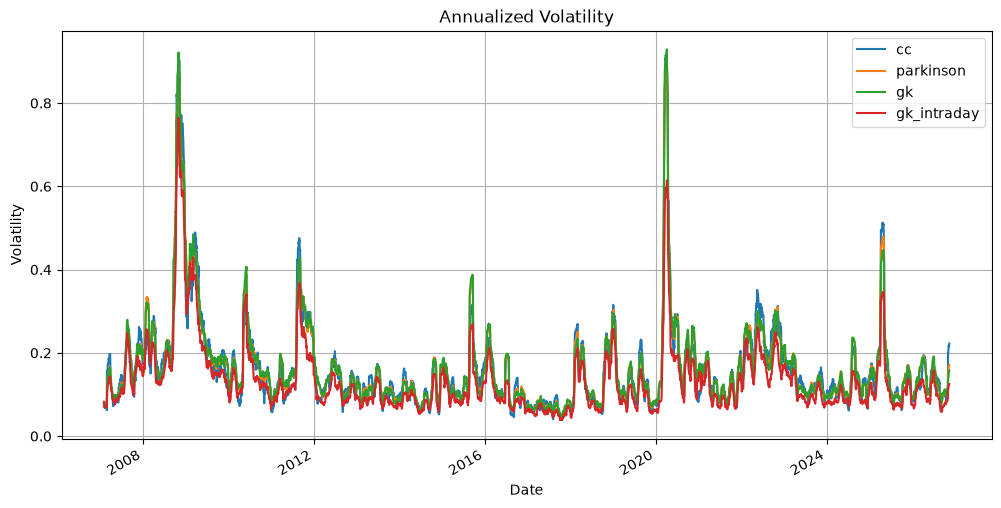

In [30]:
annualize(est.rolling(21).mean()).plot(title="Annualized Volatility", figsize=(12, 6), grid=True, xlabel="Date", ylabel="Volatility")

TODO: GK (with overnight) is slightly above cc in some years (2009, 2010, 2020) and below in others (2022, 2025). Possible link with intraday mean reversion vs. trending days. Revisit later.